In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
transactions = pd.read_csv(
    "../data/processed/fraud_transaction_features.csv"
)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

print("Shape:", transactions.shape)
transactions.head()

Shape: (200000, 23)


,transaction_id,customer_id,timestamp,transaction_type,merchant_id,merchant_category,device_id,is_fraud,amount,hour,...,customer_std_amount,customer_median_amount,amount_deviation,previous_timestamp,seconds_since_previous,date,transactions_24h,spending_24h,previous_device,device_changed
0,1042065,100001,2025-03-29 21:37:35,Card,11346,Financial,20714,0,13351.43,21,...,3647.497736,1717.555,3.188675,NaN,86400.0,2025-03-29,1,13351.43,NaN,0
1,968859,100001,2025-05-04 10:28:58,Card,10253,Healthcare,20821,0,4474.74,10,...,3647.497736,1717.555,0.755704,2025-03-29 21:37:35,3070283.0,2025-05-04,1,4474.74,20714.0,1
2,1025968,100001,2025-05-07 06:23:39,UPI,11753,Electronics,22961,0,11412.17,6,...,3647.497736,1717.555,2.657153,2025-05-04 10:28:58,244481.0,2025-05-07,1,11412.17,20821.0,1
3,940082,100001,2025-05-08 15:05:13,Card,11663,Travel,22245,0,2012.79,15,...,3647.497736,1717.555,0.080920,2025-05-07 06:23:39,117694.0,2025-05-08,1,2012.79,22961.0,1
4,915192,100001,2025-05-16 13:25:24,UPI,10372,Retail,22056,0,398.77,13,...,3647.497736,1717.555,-0.361460,2025-05-08 15:05:13,685211.0,2025-05-16,1,398.77,22245.0,1


In [3]:
graph_columns = [
    "customer_id",
    "merchant_id",
    "device_id",
    "amount",
    "is_fraud"
]

print(transactions[graph_columns].head())

   customer_id  merchant_id  device_id    amount  is_fraud
0       100001        11346      20714  13351.43         0
1       100001        10253      20821   4474.74         0
2       100001        11753      22961  11412.17         0
3       100001        11663      22245   2012.79         0
4       100001        10372      22056    398.77         0


In [4]:
G = nx.Graph()

In [5]:
for customer in transactions["customer_id"].unique():
    G.add_node(
        f"C_{customer}",
        node_type="customer"
    )

for merchant in transactions["merchant_id"].unique():
    G.add_node(
        f"M_{merchant}",
        node_type="merchant"
    )

for device in transactions["device_id"].unique():
    G.add_node(
        f"D_{device}",
        node_type="device"
    )

In [6]:
print("Nodes:", G.number_of_nodes())

Nodes: 15000


In [7]:
customer_merchant = (
    transactions
    .groupby(
        ["customer_id", "merchant_id"]
    )
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

In [8]:
for _, row in customer_merchant.iterrows():

    customer_node = f"C_{row['customer_id']}"
    merchant_node = f"M_{row['merchant_id']}"

    G.add_edge(
        customer_node,
        merchant_node,
        relationship="transaction",
        transaction_count=row["transaction_count"],
        total_amount=row["total_amount"],
        fraud_count=row["fraud_count"]
    )

In [9]:
customer_device = (
    transactions
    .groupby(
        ["customer_id", "device_id"]
    )
    .agg(
        transaction_count=("transaction_id", "count"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

In [10]:
for _, row in customer_device.iterrows():

    customer_node = f"C_{row['customer_id']}"
    device_node = f"D_{row['device_id']}"

    G.add_edge(
        customer_node,
        device_node,
        relationship="device",
        transaction_count=row["transaction_count"],
        fraud_count=row["fraud_count"]
    )

In [11]:
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

Total nodes: 27000
Total edges: 398343


In [14]:
node_types = pd.Series(
    nx.get_node_attributes(
        G,
        "node_type"
    )
)

print(node_types.value_counts())

customer    10000
device       3000
merchant     2000
Name: count, dtype: int64


In [16]:
# Check node types safely

node_types = pd.Series(
    [
        data.get("node_type", "unknown")
        for _, data in G.nodes(data=True)
    ]
)

print("Node type distribution:")
print(node_types.value_counts())

print("\nTotal nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

Node type distribution:
unknown     12000
customer    10000
device       3000
merchant     2000
Name: count, dtype: int64

Total nodes: 27000
Total edges: 398343


In [17]:
missing_node_types = [
    node
    for node, data in G.nodes(data=True)
    if "node_type" not in data
]

print("Nodes missing node_type:", len(missing_node_types))
print(missing_node_types[:20])

Nodes missing node_type: 12000
['C_100001.0', 'M_10019.0', 'M_10080.0', 'M_10087.0', 'M_10225.0', 'M_10227.0', 'M_10241.0', 'M_10253.0', 'M_10308.0', 'M_10340.0', 'M_10355.0', 'M_10372.0', 'M_10738.0', 'M_10816.0', 'M_10857.0', 'M_11190.0', 'M_11295.0', 'M_11346.0', 'M_11370.0', 'M_11445.0']


In [18]:
for node in missing_node_types:
    if str(node).startswith("C_"):
        G.nodes[node]["node_type"] = "customer"
    elif str(node).startswith("M_"):
        G.nodes[node]["node_type"] = "merchant"
    elif str(node).startswith("D_"):
        G.nodes[node]["node_type"] = "device"
    else:
        G.nodes[node]["node_type"] = "unknown"

In [19]:
node_types = pd.Series(
    nx.get_node_attributes(G, "node_type")
)

print(node_types.value_counts())

customer    20000
merchant     4000
device       3000
Name: count, dtype: int64


In [21]:
device_nodes = [
    node
    for node, data in G.nodes(data=True)
    if data["node_type"] == "device"
]

In [22]:
device_degree = pd.DataFrame({
    "device_id": [
        node.replace("D_", "")
        for node in device_nodes
    ],
    "customer_connections": [
        G.degree(node)
        for node in device_nodes
    ]
})

In [23]:
device_degree = device_degree.sort_values(
    "customer_connections",
    ascending=False
)

device_degree.head(15)

,device_id,customer_connections
551,22101,95
311,21621,93
1642,21653,93
193,22757,93
1014,21218,91
1447,21389,90
2910,22825,90
1398,21335,90
602,21225,90
507,22830,89


In [24]:
device_risk = (
    transactions
    .groupby("device_id")
    .agg(
        customers=("customer_id", "nunique"),
        transactions=("transaction_id", "count"),
        fraudulent_transactions=("is_fraud", "sum"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

In [25]:
device_risk["fraud_rate"] = (
    device_risk["fraudulent_transactions"]
    / device_risk["transactions"]
)

In [26]:
suspicious_devices = device_risk.sort_values(
    [
        "fraudulent_transactions",
        "customers"
    ],
    ascending=False
)

suspicious_devices.head(20)

,device_id,customers,transactions,fraudulent_transactions,total_amount,fraud_rate
2279,22280,83,85,8,207063.54,0.094118
2793,22794,80,80,8,226225.27,0.100000
962,20963,78,79,8,168055.26,0.101266
2853,22854,70,70,8,180524.36,0.114286
560,20561,66,66,8,166325.17,0.121212
766,20767,57,58,8,134717.54,0.137931
1903,21904,84,84,7,242326.72,0.083333
2394,22395,82,82,7,173884.15,0.085366
334,20335,81,81,7,183606.98,0.086420
2427,22428,80,80,7,166412.08,0.087500


In [27]:
customer_nodes = [
    node
    for node, data in G.nodes(data=True)
    if data["node_type"] == "customer"
]

In [28]:
centrality = nx.degree_centrality(G)

In [29]:
customer_centrality = pd.DataFrame({
    "customer_id": [
        node.replace("C_", "")
        for node in customer_nodes
    ],
    "degree_centrality": [
        centrality[node]
        for node in customer_nodes
    ]
})

customer_centrality = customer_centrality.sort_values(
    "degree_centrality",
    ascending=False
)

customer_centrality.head(20)

,customer_id,degree_centrality
815,100816,0.001370
4719,104720,0.001370
10815,100816.0,0.001333
2500,102501,0.001333
12500,102501.0,0.001333
14719,104720.0,0.001333
9551,109552,0.001333
8095,108096,0.001296
16588,106589.0,0.001296
11620,101621.0,0.001296


In [30]:
customer_fraud = (
    transactions
    .groupby("customer_id")
    .agg(
        transactions=("transaction_id", "count"),
        fraudulent_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

customer_fraud["fraud_rate"] = (
    customer_fraud["fraudulent_transactions"]
    / customer_fraud["transactions"]
)

In [32]:
# Ensure customer_id has the same datatype in both DataFrames

customer_fraud["customer_id"] = (
    customer_fraud["customer_id"]
    .astype(str)
    .str.strip()
)

customer_centrality["customer_id"] = (
    customer_centrality["customer_id"]
    .astype(str)
    .str.strip()
)

customer_graph_risk = customer_fraud.merge(
    customer_centrality,
    on="customer_id",
    how="left"
)

print("Merged shape:", customer_graph_risk.shape)
customer_graph_risk.head()

Merged shape: (10000, 5)


,customer_id,transactions,fraudulent_transactions,fraud_rate,degree_centrality
0,100001,22,0,0.000000,0.000815
1,100002,22,1,0.045455,0.000778
2,100003,10,1,0.100000,0.000370
3,100004,23,2,0.086957,0.000852
4,100005,16,0,0.000000,0.000593


In [33]:
# -------------------------------
# CUSTOMER GRAPH RISK
# -------------------------------

customer_fraud = (
    transactions
    .groupby("customer_id")
    .agg(
        transactions=("transaction_id", "count"),
        fraudulent_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

# Standardize ID type
customer_fraud["customer_id"] = (
    customer_fraud["customer_id"]
    .astype(str)
    .str.strip()
)

customer_centrality["customer_id"] = (
    customer_centrality["customer_id"]
    .astype(str)
    .str.strip()
)

# Fraud rate
customer_fraud["fraud_rate"] = (
    customer_fraud["fraudulent_transactions"]
    / customer_fraud["transactions"]
)

# Merge
customer_graph_risk = customer_fraud.merge(
    customer_centrality,
    on="customer_id",
    how="left"
)

# Handle missing centrality
customer_graph_risk["degree_centrality"] = (
    customer_graph_risk["degree_centrality"]
    .fillna(0)
)

print("Customer graph risk shape:")
print(customer_graph_risk.shape)

customer_graph_risk.head()

Customer graph risk shape:
(10000, 5)


,customer_id,transactions,fraudulent_transactions,fraud_rate,degree_centrality
0,100001,22,0,0.000000,0.000815
1,100002,22,1,0.045455,0.000778
2,100003,10,1,0.100000,0.000370
3,100004,23,2,0.086957,0.000852
4,100005,16,0,0.000000,0.000593


In [34]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

customer_graph_risk[
    ["fraud_rate_scaled", "centrality_scaled"]
] = scaler.fit_transform(
    customer_graph_risk[
        ["fraud_rate", "degree_centrality"]
    ]
)

customer_graph_risk["graph_risk_score"] = (
    0.6 * customer_graph_risk["fraud_rate_scaled"]
    + 0.4 * customer_graph_risk["centrality_scaled"]
) * 100

customer_graph_risk.sort_values(
    "graph_risk_score",
    ascending=False
).head(20)

,customer_id,transactions,fraudulent_transactions,fraud_rate,degree_centrality,fraud_rate_scaled,centrality_scaled,graph_risk_score
4310,104311,28,6,0.214286,0.001037,0.803571,0.709677,76.601382
3180,103181,20,5,0.250000,0.000741,0.937500,0.451613,74.314516
3556,103557,21,5,0.238095,0.000778,0.892857,0.483871,72.926267
9287,109288,15,4,0.266667,0.000556,1.000000,0.290323,71.612903
9253,109254,15,4,0.266667,0.000556,1.000000,0.290323,71.612903
3616,103617,16,4,0.250000,0.000593,0.937500,0.322581,69.153226
4094,104095,26,5,0.192308,0.000963,0.721154,0.645161,69.075682
1312,101313,26,5,0.192308,0.000963,0.721154,0.645161,69.075682
9701,109702,31,5,0.161290,0.001148,0.604839,0.806452,68.548387
8177,108178,17,4,0.235294,0.000630,0.882353,0.354839,67.134725


In [35]:
print(customer_fraud["customer_id"].dtype)
print(customer_centrality["customer_id"].dtype)

str
str


In [36]:
print("customer_fraud samples:")
print(customer_fraud["customer_id"].head(10).tolist())

print("\ncustomer_centrality samples:")
print(customer_centrality["customer_id"].head(10).tolist())

customer_fraud samples:
['100001', '100002', '100003', '100004', '100005', '100006', '100007', '100008', '100009', '100010']

customer_centrality samples:
['100816', '104720', '100816.0', '102501', '102501.0', '104720.0', '109552', '108096', '106589.0', '101621.0']


In [37]:
print(
    "Fraud ID example:",
    repr(customer_fraud["customer_id"].iloc[0])
)

print(
    "Centrality ID example:",
    repr(customer_centrality["customer_id"].iloc[0])
)

Fraud ID example: '100001'
Centrality ID example: '100816'


In [38]:
def normalize_customer_id(series):
    return (
        series
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

customer_fraud["customer_id"] = normalize_customer_id(
    customer_fraud["customer_id"]
)

customer_centrality["customer_id"] = normalize_customer_id(
    customer_centrality["customer_id"]
)

In [39]:
print(customer_fraud["customer_id"].dtype)
print(customer_centrality["customer_id"].dtype)

print(
    customer_fraud["customer_id"].head().tolist()
)

print(
    customer_centrality["customer_id"].head().tolist()
)

str
str
['100001', '100002', '100003', '100004', '100005']
['100816', '104720', '100816', '102501', '102501']


In [40]:
print("customer_fraud:")
print(customer_fraud["customer_id"].head(10).map(repr).tolist())

print("\ncustomer_centrality:")
print(customer_centrality["customer_id"].head(10).map(repr).tolist())

print("\nFirst value types:")
print(type(customer_fraud["customer_id"].iloc[0]))
print(type(customer_centrality["customer_id"].iloc[0]))

print("\nLengths:")
print(customer_fraud["customer_id"].head(10).map(len).tolist())
print(customer_centrality["customer_id"].head(10).map(len).tolist())

customer_fraud:
["'100001'", "'100002'", "'100003'", "'100004'", "'100005'", "'100006'", "'100007'", "'100008'", "'100009'", "'100010'"]

customer_centrality:
["'100816'", "'104720'", "'100816'", "'102501'", "'102501'", "'104720'", "'109552'", "'108096'", "'106589'", "'101621'"]

First value types:
<class 'str'>
<class 'str'>

Lengths:
[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]
[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]


In [41]:
# Calculate degree centrality
centrality = nx.degree_centrality(G)

# Build customer centrality dataframe
customer_centrality = pd.DataFrame({
    "customer_id": [
        str(node).replace("C_", "").strip()
        for node, data in G.nodes(data=True)
        if data.get("node_type") == "customer"
    ],
    "degree_centrality": [
        centrality[node]
        for node, data in G.nodes(data=True)
        if data.get("node_type") == "customer"
    ]
})

# Remove any accidental duplicate customer IDs
customer_centrality = (
    customer_centrality
    .groupby("customer_id", as_index=False)
    .agg(
        degree_centrality=("degree_centrality", "max")
    )
)

print("Customer centrality shape:", customer_centrality.shape)
print("Unique customer IDs:", customer_centrality["customer_id"].nunique())
print("Duplicate IDs:", customer_centrality["customer_id"].duplicated().sum())

customer_centrality.head()

Customer centrality shape: (20000, 2)
Unique customer IDs: 20000
Duplicate IDs: 0


,customer_id,degree_centrality
0,100001,0.000815
1,100001.0,0.000815
2,100002,0.000778
3,100002.0,0.000815
4,100003,0.000370


In [42]:
customer_fraud = (
    transactions
    .groupby("customer_id")
    .agg(
        transactions=("transaction_id", "count"),
        fraudulent_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

customer_fraud["customer_id"] = (
    customer_fraud["customer_id"]
    .astype(str)
    .str.strip()
)

customer_fraud["fraud_rate"] = (
    customer_fraud["fraudulent_transactions"]
    / customer_fraud["transactions"]
)

In [43]:
customer_graph_risk = customer_fraud.merge(
    customer_centrality,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Shape:", customer_graph_risk.shape)
print("Missing centrality:", customer_graph_risk["degree_centrality"].isna().sum())

customer_graph_risk.head()

Shape: (10000, 5)
Missing centrality: 0


,customer_id,transactions,fraudulent_transactions,fraud_rate,degree_centrality
0,100001,22,0,0.000000,0.000815
1,100002,22,1,0.045455,0.000778
2,100003,10,1,0.100000,0.000370
3,100004,23,2,0.086957,0.000852
4,100005,16,0,0.000000,0.000593


In [44]:
print("Fraud customers:", customer_fraud["customer_id"].nunique())
print("Centrality customers:", customer_centrality["customer_id"].nunique())
print("Merged customers:", customer_graph_risk["customer_id"].nunique())

Fraud customers: 10000
Centrality customers: 20000
Merged customers: 10000


In [45]:
print(customer_fraud["customer_id"].dtype)
print(customer_centrality["customer_id"].dtype)

str
str


In [47]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

customer_graph_risk[
    [
        "fraud_rate_scaled",
        "centrality_scaled"
    ]
] = scaler.fit_transform(
    customer_graph_risk[
        [
            "fraud_rate",
            "degree_centrality"
        ]
    ]
)

In [48]:
customer_graph_risk["graph_risk_score"] = (
    0.6 * customer_graph_risk["fraud_rate_scaled"]
    + 0.4 * customer_graph_risk["centrality_scaled"]
) * 100

In [49]:
customer_graph_risk = customer_graph_risk.sort_values(
    "graph_risk_score",
    ascending=False
)

customer_graph_risk.head(20)

,customer_id,transactions,fraudulent_transactions,fraud_rate,degree_centrality,fraud_rate_scaled,centrality_scaled,graph_risk_score
4310,104311,28,6,0.214286,0.001037,0.803571,0.709677,76.601382
3180,103181,20,5,0.250000,0.000741,0.937500,0.451613,74.314516
3556,103557,21,5,0.238095,0.000778,0.892857,0.483871,72.926267
9287,109288,15,4,0.266667,0.000556,1.000000,0.290323,71.612903
9253,109254,15,4,0.266667,0.000556,1.000000,0.290323,71.612903
3616,103617,16,4,0.250000,0.000593,0.937500,0.322581,69.153226
4094,104095,26,5,0.192308,0.000963,0.721154,0.645161,69.075682
1312,101313,26,5,0.192308,0.000963,0.721154,0.645161,69.075682
9701,109702,31,5,0.161290,0.001148,0.604839,0.806452,68.548387
8177,108178,17,4,0.235294,0.000630,0.882353,0.354839,67.134725


In [50]:
components = list(
    nx.connected_components(G)
)

component_sizes = sorted(
    [len(component) for component in components],
    reverse=True
)

print("Number of connected components:", len(components))
print("Largest component:", component_sizes[0])

Number of connected components: 2002
Largest component: 13000


In [51]:
fraud_pairs = set(
    zip(
        "C_" + transactions.loc[
            transactions["is_fraud"] == 1,
            "customer_id"
        ].astype(str),
        "M_" + transactions.loc[
            transactions["is_fraud"] == 1,
            "merchant_id"
        ].astype(str)
    )
)

In [52]:
top_customers = (
    customer_graph_risk
    .head(10)["customer_id"]
    .astype(str)
    .tolist()
)

sub_nodes = []

for customer in top_customers:

    node = f"C_{customer}"

    if node in G:
        sub_nodes.append(node)

        sub_nodes.extend(
            list(G.neighbors(node))
        )

subgraph = G.subgraph(
    list(set(sub_nodes))
).copy()

print(
    "Subgraph nodes:",
    subgraph.number_of_nodes()
)

print(
    "Subgraph edges:",
    subgraph.number_of_edges()
)

Subgraph nodes: 220
Subgraph edges: 215


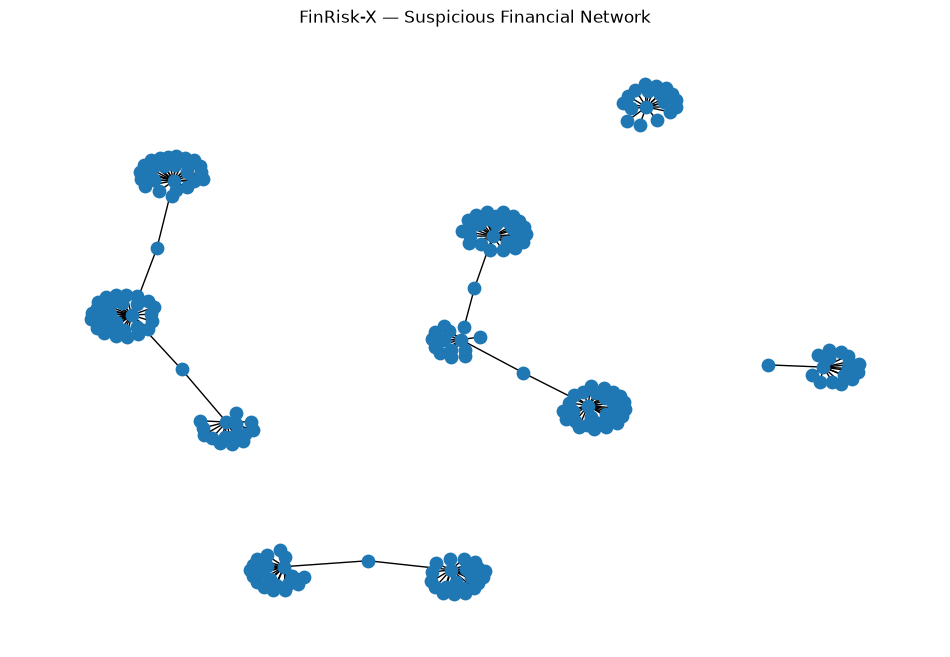

In [53]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    subgraph,
    seed=42
)

nx.draw_networkx(
    subgraph,
    pos,
    with_labels=False,
    node_size=80
)

plt.title(
    "FinRisk-X — Suspicious Financial Network"
)

plt.axis("off")
plt.show()

In [54]:
customer_graph_risk.to_csv(
    "../data/processed/customer_graph_risk.csv",
    index=False
)

suspicious_devices.to_csv(
    "../data/processed/suspicious_devices.csv",
    index=False
)

print("Graph analytics artifacts saved.")

Graph analytics artifacts saved.


In [ ]:
import pickle

with open(
    "../models/finrisk_transaction_graph.pkl",
    "wb"
) as f:
    pickle.dump(G, f)

print("Graph saved successfully.")